# Lorenz–96 hybrid residual ensembles

All objectives use the identical circular-convolution architecture and paired initialization.
This is a hybrid forecast task using the deterministic numerical forecast as a shared input.
Learning rates and checkpoints are selected on validation data only. The earlier pilot test
set is reused: this remains exploratory. Shading is one training-seed standard deviation,
not a confidence interval. Paired bootstrap results are in `paired_comparisons.csv`.

The source/data/architecture audit must pass before production figures can be drawn.
Per-lead ensembles are conditional marginals, not coherent multilead trajectories.

Dotted method curves in the joint-score figure use twice as many solver steps.
The shuffle effect is shuffled minus original variogram score; positive values
mean shuffling worsens that score. The rank-bin uniform line is approximate
because a finite ensemble has a discrete rank distribution.

In [1]:
from pathlib import Path
import json
import os
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.family':'serif','font.serif':['DejaVu Serif'],
    'font.size':14,'axes.labelsize':16,'lines.linewidth':2,'legend.frameon':False,
    'xtick.direction':'in','ytick.direction':'in','axes.grid':True})
# Retain the existing Lorenz notebook's portable mathtext convention.
COLORS={'flow_matching':'forestgreen','riesz':'steelblue','energy_score':'purple','riesz_no_repulsion':'darkorange'}
LABELS={'flow_matching':'Flow matching','riesz':'MMD/Riesz','energy_score':'Energy score','riesz_no_repulsion':'No repulsion'}


In [2]:
repo=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'experiments/lorenz96_residual_20261030/config.json').exists())
# An explicit override is only for testing this notebook against audited smoke artifacts.
result_dir=Path(os.environ['L96_NOTEBOOK_RESULT']) if 'L96_NOTEBOOK_RESULT' in os.environ else repo/'results/lorenz96/residual_20261030/production'
figure_dir=result_dir/'figures'
audit=json.loads((result_dir/'audit.json').read_text())
assert json.loads((result_dir/'ready.json').read_text())['complete']
assert audit['passed'] and audit['architecture_identical']
config=json.loads((result_dir/'config.json').read_text())
selection=json.loads((result_dir/'selection.json').read_text())
methods,seeds=config['methods'],config['seeds']
leads=np.array(config['lead_times'])
figure_dir.mkdir(parents=True,exist_ok=True)
values={}
for tag in ['selected','equal_updates','equal_time','refinement']:
    values[tag]={}
    for method in methods:
        runs=[]
        for seed in seeds:
            with np.load(result_dir/'runs'/f'{method}_seed{seed}'/f'{tag}.npz') as a:
                assert a['ensemble'].shape[1:]==(len(leads),config['ensemble_size'],config['dimension'])
                runs.append({k:a[k].mean(0) for k in a.files if k!='ensemble'})
        values[tag][method]={k:np.stack([r[k] for r in runs]) for k in runs[0]}
with np.load(result_dir/'baselines.npz') as a:
    baselines={k:a[k].mean(0) for k in a.files}
print('Results:',result_dir)
print('Architecture equality:',audit['architecture_identical'])
print('Validation-selected learning rates:',{m:s['lr'] for m,s in selection.items()})
print('Competence gate:',json.loads((result_dir/'competence.json').read_text()))


Results: /home/zongchen/mmd_flow_hudson_new/results/lorenz96/residual_20261030/production
Architecture equality: True
Validation-selected learning rates: {'flow_matching': 0.003, 'riesz': 0.003, 'energy_score': 0.003, 'riesz_no_repulsion': 0.003}
Competence gate: {'passed': True, 'smoke': False, 'criterion': 'Validation FM short-lead CRPS beats deterministic control and 90% coverage is between 70% and 98%', 'fm': {'step': 3000, 'training_seconds': 45.411480490583926, 'selection_score': 0.47822663475050625, 'crps': [0.3617820608426853, 0.6310917278947439, 1.1779495524471204], 'coverage90': [0.8263183593749998, 0.8402954101562499, 0.81214599609375], 'mean_rmse': [0.14196250361213217, 0.29259515730066765, 0.8354834037644895], 'sampling_seconds': 0.2170175272040069}, 'deterministic_crps': [0.5105240530070669, 0.9012199860469025, 1.7626893966316912]}


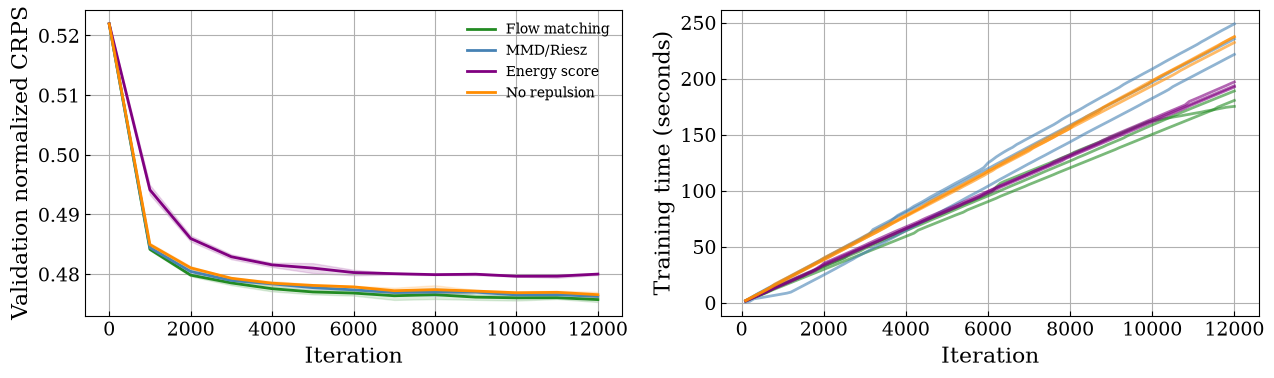

In [3]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
for method in methods:
    curves=[]
    for seed in seeds:
        rows=json.loads((result_dir/'runs'/f'{method}_seed{seed}'/'validation.json').read_text())
        steps=np.array([r['step'] for r in rows])
        curves.append([r['selection_score'] for r in rows])
    curves=np.array(curves)
    axes[0].plot(steps,curves.mean(0),color=COLORS[method],label=LABELS[method])
    axes[0].fill_between(steps,curves.mean(0)-curves.std(0),curves.mean(0)+curves.std(0),color=COLORS[method],alpha=.15)
    for seed in seeds:
        rows=[json.loads(line) for line in (result_dir/'runs'/f'{method}_seed{seed}'/'training.jsonl').read_text().splitlines()]
        axes[1].plot([r['step'] for r in rows],[r['training_seconds'] for r in rows],color=COLORS[method],alpha=.6)
axes[0].set(xlabel='Iteration',ylabel='Validation normalized CRPS')
axes[1].set(xlabel='Iteration',ylabel='Training time (seconds)')
axes[0].legend(fontsize=10)
fig.tight_layout();fig.savefig(figure_dir/'validation_and_cost.pdf',bbox_inches='tight');fig.savefig(figure_dir/'validation_and_cost.png',dpi=150,bbox_inches='tight');plt.show()


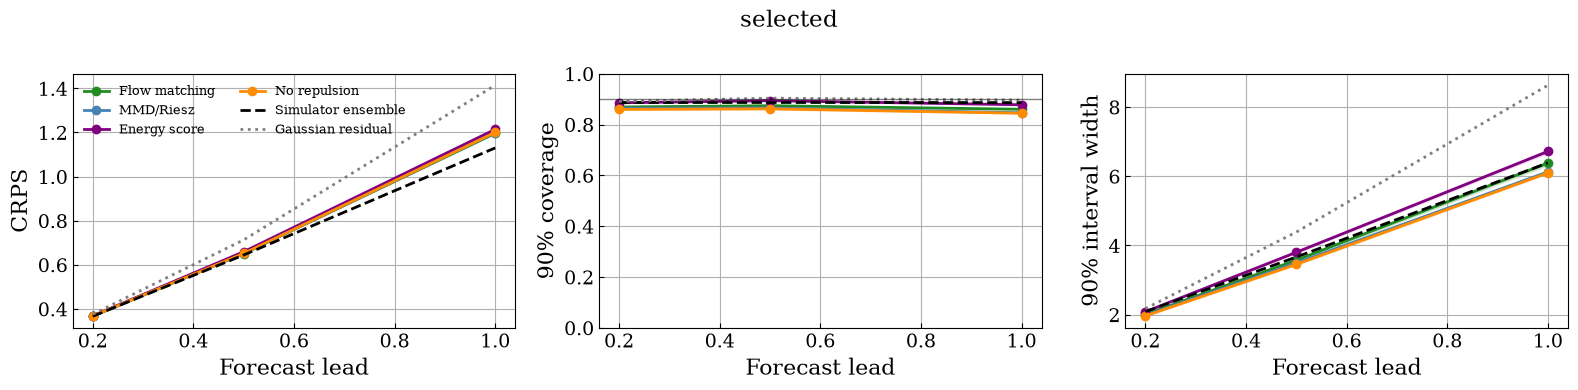

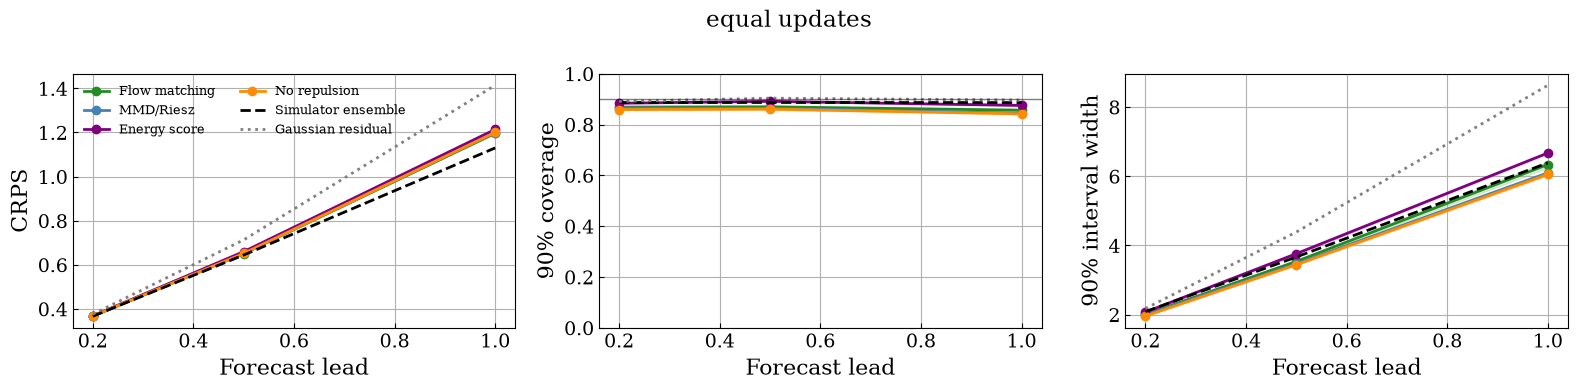

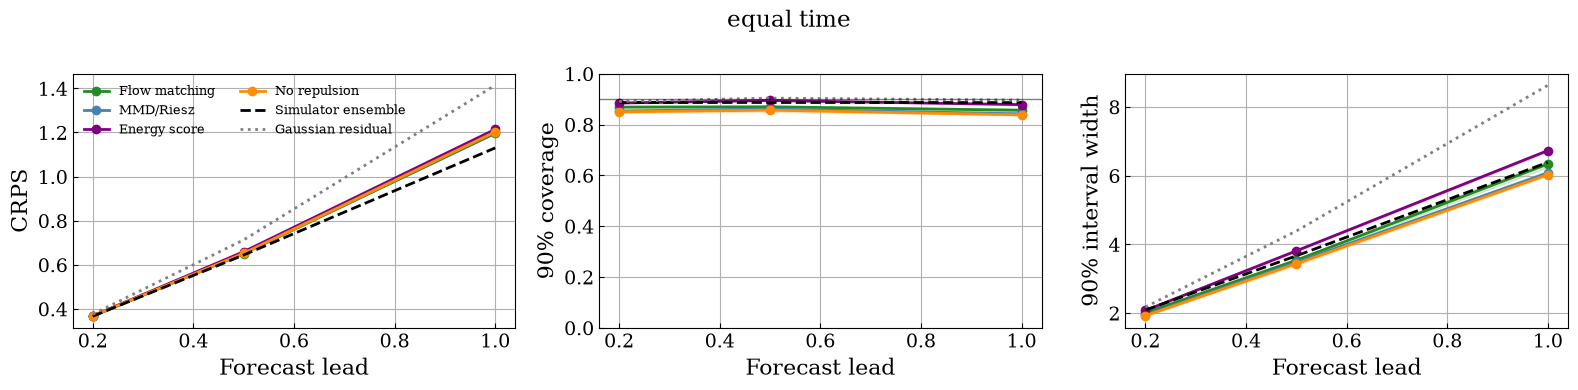

In [4]:
for tag in ['selected','equal_updates','equal_time']:
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    for ax,key,label in zip(axes,['crps','coverage90','width90'],['CRPS','90% coverage','90% interval width']):
        for method in methods:
            a=values[tag][method][key]
            ax.plot(leads,a.mean(0),marker='o',color=COLORS[method],label=LABELS[method])
            ax.fill_between(leads,a.mean(0)-a.std(0),a.mean(0)+a.std(0),color=COLORS[method],alpha=.15)
        ax.plot(leads,baselines['simulator_ensemble__'+key],'k--',label='Simulator ensemble')
        ax.plot(leads,baselines['gaussian_residual__'+key],color='gray',linestyle=':',label='Gaussian residual')
        ax.set(xlabel='Forecast lead',ylabel=label)
    axes[1].axhline(.9,color='black',linewidth=1,alpha=.5);axes[1].set_ylim(0,1)
    axes[0].legend(fontsize=9,ncol=2)
    fig.suptitle(tag.replace('_',' '));fig.tight_layout()
    fig.savefig(figure_dir/f'{tag}_calibration.pdf',bbox_inches='tight');fig.savefig(figure_dir/f'{tag}_calibration.png',dpi=150,bbox_inches='tight');plt.show()


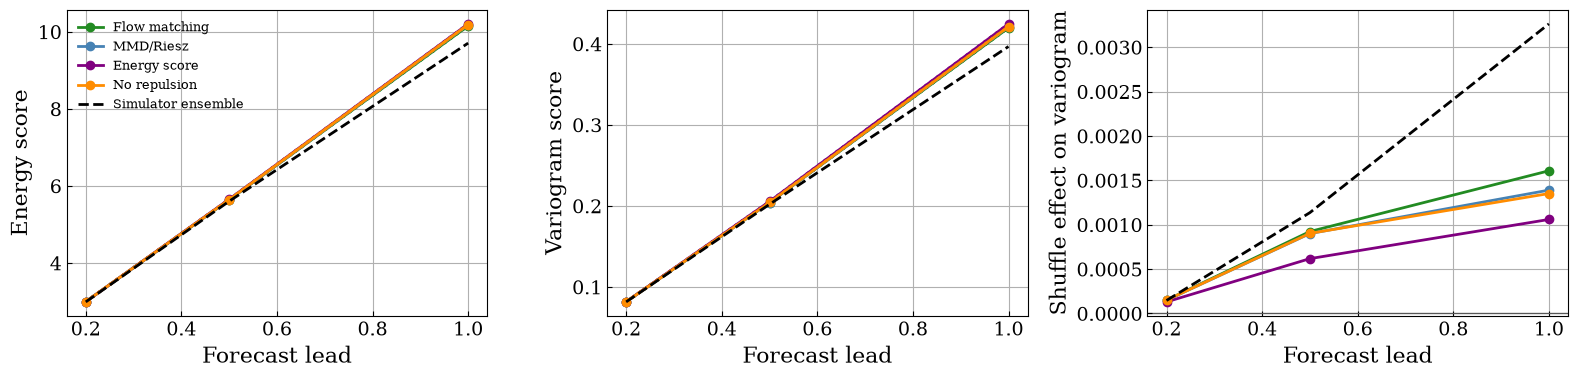

In [5]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,key,label in zip(axes,['energy_score','variogram','shuffle_variogram_difference'],['Energy score','Variogram score','Shuffle effect on variogram']):
    for method in methods:
        a=values['selected'][method][key]
        ax.plot(leads,a.mean(0),marker='o',color=COLORS[method],label=LABELS[method])
        if key!='shuffle_variogram_difference':
            ax.plot(leads,values['refinement'][method][key].mean(0),color=COLORS[method],linestyle=':')
    ax.plot(leads,baselines['simulator_ensemble__'+key],'k--',label='Simulator ensemble')
    ax.set(xlabel='Forecast lead',ylabel=label)
axes[2].axhline(0,color='black',linewidth=1,alpha=.5)
axes[0].legend(fontsize=9);fig.tight_layout()
fig.savefig(figure_dir/'joint_structure_and_refinement.pdf',bbox_inches='tight');fig.savefig(figure_dir/'joint_structure_and_refinement.png',dpi=150,bbox_inches='tight');plt.show()


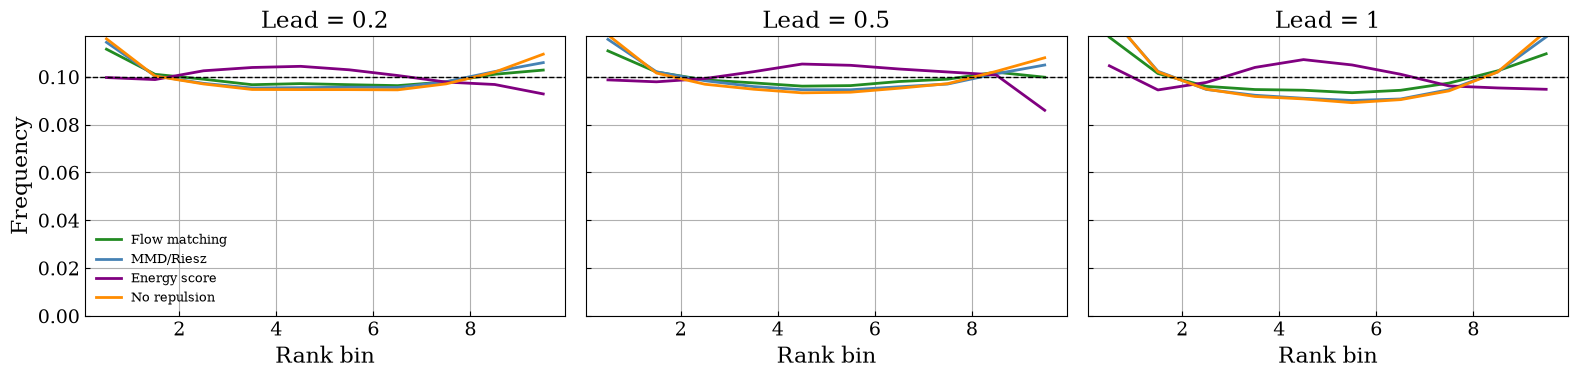

In [6]:
fig,axes=plt.subplots(1,len(leads),figsize=(16,4),sharey=True)
for li,ax in enumerate(axes):
    for method in methods:
        ranks=np.array([values['selected'][method][f'rank_bin_{k}'].mean(0)[li] for k in range(10)])
        ax.plot(np.arange(10)+.5,ranks,color=COLORS[method],label=LABELS[method])
    ax.axhline(.1,color='black',linestyle='--',linewidth=1)
    ax.set(xlabel='Rank bin',title=f'Lead = {leads[li]:g}',ylim=(0,None))
axes[0].set_ylabel('Frequency');axes[0].legend(fontsize=9);fig.tight_layout()
fig.savefig(figure_dir/'rank_histograms.pdf',bbox_inches='tight');fig.savefig(figure_dir/'rank_histograms.png',dpi=150,bbox_inches='tight');plt.show()
